In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = Path(r"D:\Upenn\Large-scaleML\result")

DISEASES = {
    "cihd_pmbb": "CIHD",
    "ckd_pmbb": "CKD",
    "hypothyroidism_pmbb": "Hypothyroidism",
    "t2d_pmbb": "T2D",
}
MODELS = {
    "clmbr-t-base":   {"label": "CLMBR-T-base",   "n_layers": 12, "color": "#2a78d6"},
    "gatortron-base": {"label": "GatorTron-base", "n_layers": 24, "color": "#eb6834"},
    "gatortronS":     {"label": "GatorTronS",     "n_layers": 24, "color": "#1baf7a"},
}
CONDITIONS = {
    "text_no_race":   {"label": "without race", "ls": "-",  "hollow": False},
    "text_with_race": {"label": "with race",    "ls": "--", "hollow": True},
}
TAU = 0.01                                  # probability threshold: 0.01, 0.02, 0.03, 0.05, 0.075, 0.10
ALPHAS = [-2, -1, 0, 1, 2]
COLORS = {-2: "#1f4e9c", -1: "#6f9fd8", 0: "#7a7a7a", 1: "#f0a070", 2: "#c2461a"}

# TPR gap between Race

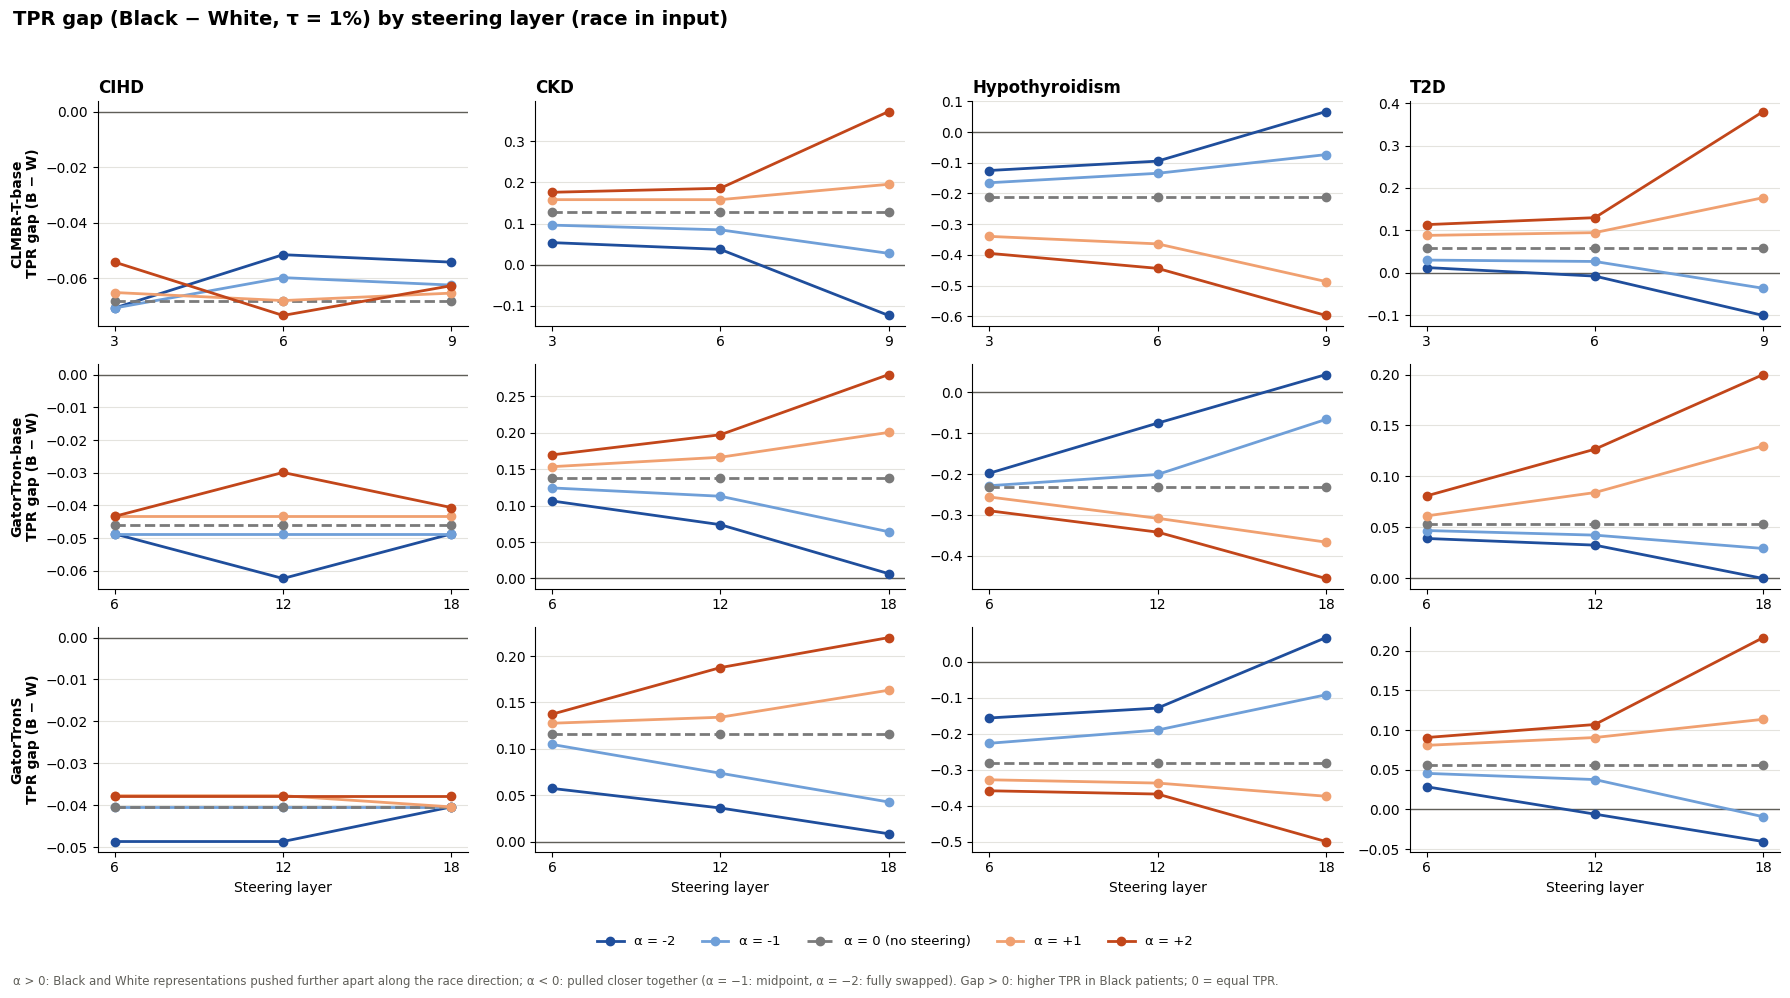

In [6]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
diseases = list(DISEASES.values())
fig, axes = plt.subplots(len(MODELS), len(DISEASES), figsize=(18, 10), sharey=False)

for r, (m, ms) in enumerate(MODELS.items()):
    for c, (dfolder, dlabel) in enumerate(DISEASES.items()):
        ax = axes[r, c]
        t = pd.read_csv(ROOT / dfolder / m / "steering" / "steer_tau.csv")
        t = t[(t["mode"] == "signed") & (t["condition"] == COND) & np.isclose(t["tau"], TAU)]

        ax.axhline(0, color="#5f5e58", lw=1)                 # no gap
        for a in ALPHAS:
            d = t[np.isclose(t["alpha"], a)].sort_values("layer")
            ax.plot(d["layer"], d["tpr_gap"], marker="o", ms=6, lw=2, color=COLORS[a],
                    ls="--" if a == 0 else "-",
                    label=f"α = {a:+d}" if a else "α = 0 (no steering)")

        ax.set_xticks(sorted(t["layer"].unique()))
        ax.grid(axis="y", color="#e4e3de", lw=0.8)
        ax.set_axisbelow(True)
        for s in ["top", "right"]:
            ax.spines[s].set_visible(False)

        if r == 0:
            ax.set_title(dlabel, loc="left", fontsize=12, fontweight="bold")
        if r == len(MODELS) - 1:
            ax.set_xlabel("Steering layer")
        if c == 0:
            ax.set_ylabel(f"{ms['label']}\nTPR gap (B − W)", fontweight="bold")

h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(ALPHAS), frameon=False, fontsize=9.5,
           bbox_to_anchor=(0.5, 0.03))
fig.text(0.01, 0.005,
         "α > 0: Black and White representations pushed further apart along the race direction; "
         "α < 0: pulled closer together (α = −1: midpoint, α = −2: fully swapped). "
         "Gap > 0: higher TPR in Black patients; 0 = equal TPR.",
         fontsize=8.5, color="#5f5e58", ha="left")
fig.suptitle(f"TPR gap (Black − White, τ = {TAU:.0%}) by steering layer "
             f"({'race in input' if COND == 'text_with_race' else 'race removed'})",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
plt.show()

# TPR gap between Steer (stratified by race)

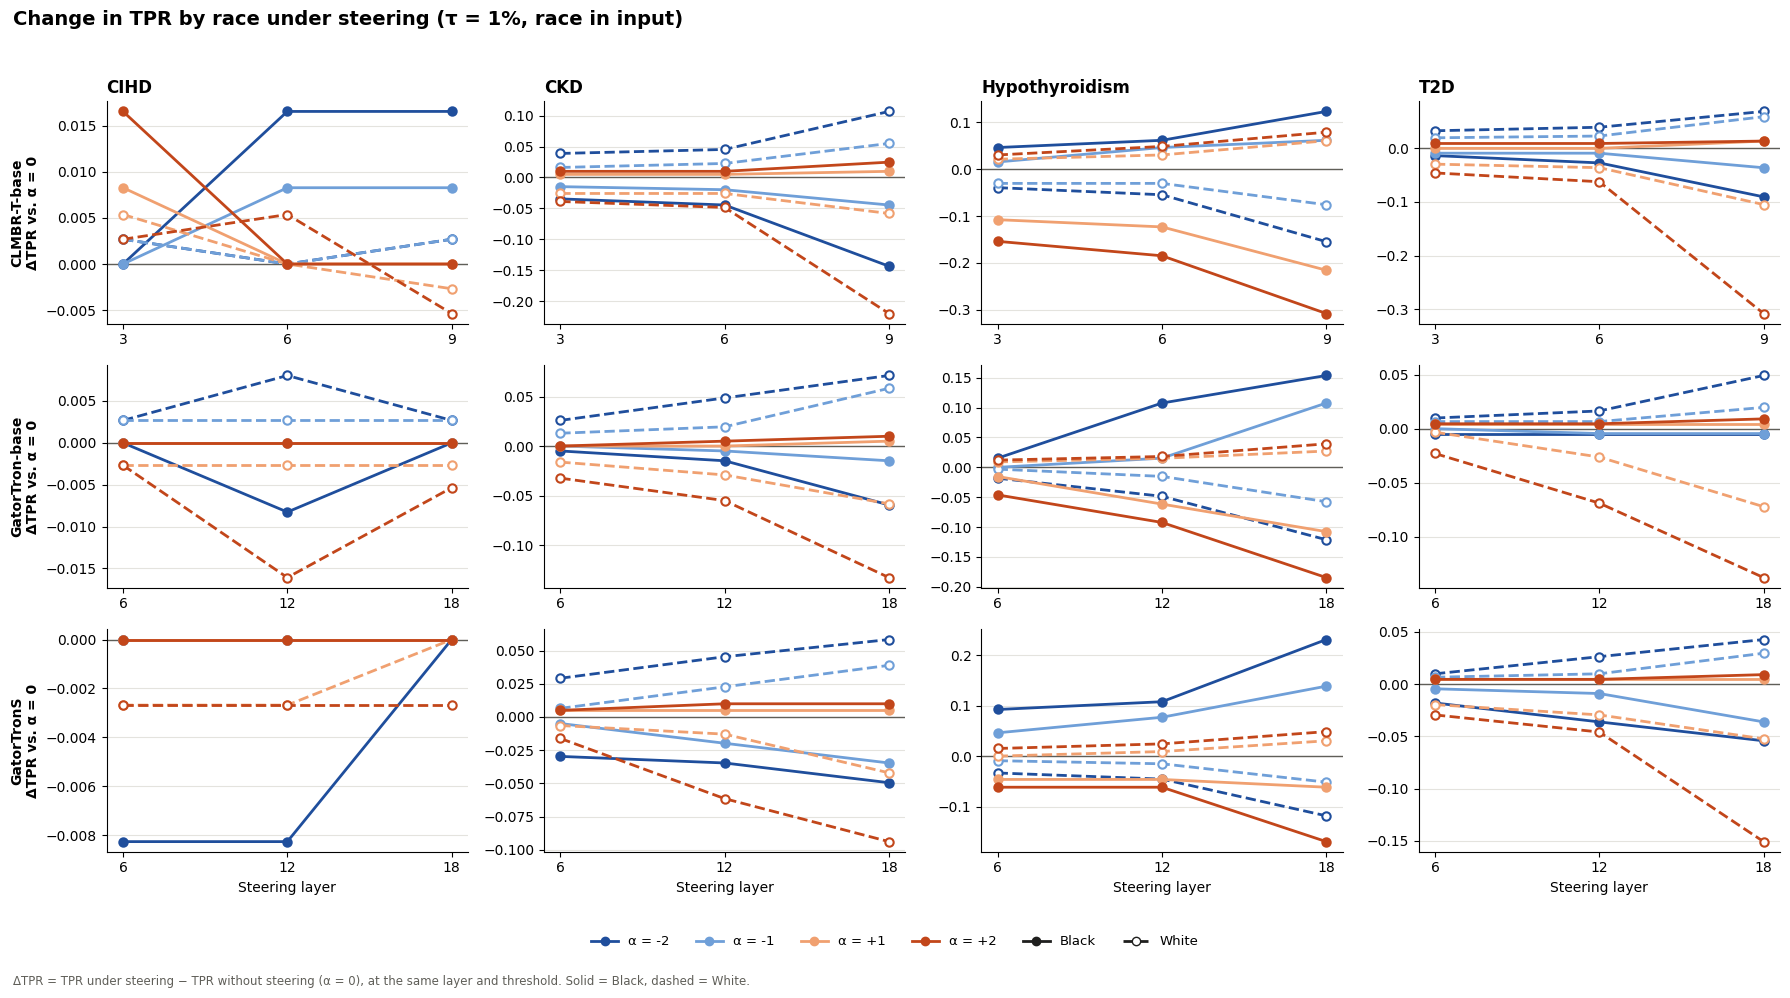

In [7]:
RACE_STYLE = {
    "black": {"label": "Black", "ls": "-",  "hollow": False},
    "white": {"label": "White", "ls": "--", "hollow": True},
}

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
fig, axes = plt.subplots(len(MODELS), len(DISEASES), figsize=(18, 10), sharey=False)

for r, (m, ms) in enumerate(MODELS.items()):
    for c, (dfolder, dlabel) in enumerate(DISEASES.items()):
        ax = axes[r, c]
        t = pd.read_csv(ROOT / dfolder / m / "steering" / "steer_tau.csv")
        t = t[(t["mode"] == "signed") & (t["condition"] == COND) & np.isclose(t["tau"], TAU)]
        base = t[np.isclose(t["alpha"], 0)].set_index("layer")[["tpr_black", "tpr_white"]]

        ax.axhline(0, color="#5f5e58", lw=1)                 # no change vs. unsteered
        for a in ALPHAS:
            if a == 0:
                continue
            d = t[np.isclose(t["alpha"], a)].set_index("layer").sort_index()
            for race, rs in RACE_STYLE.items():
                col = f"tpr_{race}"
                delta = d[col] - base.loc[d.index, col]
                ax.plot(delta.index, delta.values, ls=rs["ls"], lw=2, color=COLORS[a],
                        marker="o", ms=6, mec=COLORS[a], mew=1.5,
                        mfc="white" if rs["hollow"] else COLORS[a])

        ax.set_xticks(sorted(t["layer"].unique()))
        ax.grid(axis="y", color="#e4e3de", lw=0.8)
        ax.set_axisbelow(True)
        for s in ["top", "right"]:
            ax.spines[s].set_visible(False)

        if r == 0:
            ax.set_title(dlabel, loc="left", fontsize=12, fontweight="bold")
        if r == len(MODELS) - 1:
            ax.set_xlabel("Steering layer")
        if c == 0:
            ax.set_ylabel(f"{ms['label']}\nΔTPR vs. α = 0", fontweight="bold")

handles = (
    [Line2D([], [], color=COLORS[a], lw=2, marker="o", label=f"α = {a:+d}") for a in ALPHAS if a != 0]
    + [Line2D([], [], color="#1f1f1e", lw=2, ls=rs["ls"], marker="o",
              mfc="white" if rs["hollow"] else "#1f1f1e", label=rs["label"])
       for rs in RACE_STYLE.values()]
)
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=9.5,
           bbox_to_anchor=(0.5, 0.03))
fig.text(0.01, 0.005,
         "ΔTPR = TPR under steering − TPR without steering (α = 0), at the same layer and threshold. "
         "Solid = Black, dashed = White.",
         fontsize=8.5, color="#5f5e58", ha="left")
fig.suptitle(f"Change in TPR by race under steering (τ = {TAU:.0%}, "
             f"{'race in input' if COND == 'text_with_race' else 'race removed'})",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
plt.show()